# Notebook 3 — Imaging Risk Model (RSNA Pneumonia → Faster R-CNN + Brixia-style severity)

**Role in the pipeline.** Runs at **t = 0** and at **every re-imaging trigger**. It detects lung opacities (bounding boxes), turns them into a **zone-based severity score**, and maps that to a calibrated probability `p_img`.
In Notebook 4 this becomes `Δ_img = logit(p_img) − logit(base rate)`, weighted by `β` = this model's Brier skill score, and held constant until the next image.

**Design decisions implemented here**
- **Detector:** torchvision Faster R-CNN (ResNet-50 FPN), COCO-pretrained, new 2-class head (background / opacity). Images resized 1024 → 512.
- **Balanced epochs:** every training image with boxes + an equal number of randomly re-drawn negatives per epoch (keeps training time reasonable on a T4).
- **Severity (Brixia-style):** the lung field is split into **6 zones** (right/left × upper/middle/lower). Each zone is graded 0–3 by the fraction covered by detected boxes → total **0–18**. Also reported: number of boxes, bilateral involvement, highest box confidence.
  *Approximation:* zones are fixed regions of the image, not a lung segmentation.
- **Severity → probability:** logistic regression (fitted on validation) from `[logit(max box score), severity total]` to the image-level "opacity present" label. RSNA has no severity labels, so the opacity label is the calibration target; severity is validated separately against the same score computed from the radiologists' boxes.
- **β = Brier skill score of `p_img` on test** (reference = always predicting the training opacity rate), clipped to [0, 1].
- **Fairness-style audit** by sex, age band and view (AP/PA) from the DICOM headers.

**Inputs:** RSNA Pneumonia Detection Challenge (`stage_2_train_labels.csv`, `stage_2_detailed_class_info.csv`, `stage_2_train_images/`).
**Settings:** GPU T4, **Internet ON** (downloads the COCO-pretrained weights once, ~160 MB).

**Outputs (`/kaggle/working/artifacts_imaging/` + zip):** detector weights, config, calibrator, metrics (incl. `beta`), `img_inference.py` loader, test-set predictions, a **demo image pool** (512-px PNGs across severity levels, so Notebook 4 does not need the RSNA dataset), plots.

## 1. Setup

In [1]:
import os, sys, glob, json, math, time, shutil, platform, warnings, copy
from multiprocessing import Pool
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, pydicom
import torch, torchvision

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
print("device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

# ---- paths --------------------------------------------------------------
def find_rsna_root():
    hits = glob.glob("/kaggle/input/**/stage_2_train_labels.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    local = os.environ.get("RSNA_DIR", ".")
    if os.path.exists(os.path.join(local, "stage_2_train_labels.csv")):
        return local
    raise FileNotFoundError("stage_2_train_labels.csv not found. Add the RSNA Pneumonia Detection Challenge as an input.")

RSNA_ROOT = find_rsna_root()
DICOM_DIR = os.path.join(RSNA_ROOT, "stage_2_train_images")
CACHE_DIR = "/tmp/rsna512" if os.path.isdir("/kaggle") else os.path.join(os.path.abspath("."), "rsna512_cache")
WORK_DIR  = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
OUT_DIR   = os.path.join(WORK_DIR, "artifacts_imaging")
PLOT_DIR  = os.path.join(OUT_DIR, "plots")
DEMO_DIR  = os.path.join(OUT_DIR, "demo_images")
for d in (CACHE_DIR, PLOT_DIR, DEMO_DIR):
    os.makedirs(d, exist_ok=True)

# ---- experiment settings -------------------------------------------------
QUICK      = os.environ.get("NB3_QUICK") == "1"      # tiny smoke-test run only
PRETRAINED = os.environ.get("NB3_PRETRAINED", "1") == "1"
IMG_SIZE, ORIG_SIZE = 512, 1024
VAL_FRAC, TEST_FRAC = 0.15, 0.15
EPOCHS      = 1 if QUICK else 5
BATCH_SIZE  = 2 if QUICK else 8
NEG_RATIO   = 1.0          # negatives per positive in each training epoch
LR, MOMENTUM, WEIGHT_DECAY, WARMUP_ITERS = 0.01, 0.9, 1e-4, (5 if QUICK else 300)
VAL_EVAL_N  = 1500         # validation images scored after each epoch (full validation set at the end)
NUM_WORKERS = 0 if QUICK else 4
DEMO_PER_TIER = 3 if QUICK else 50

print("RSNA root:", RSNA_ROOT, "| cache:", CACHE_DIR, "| output:", OUT_DIR, "| quick:", QUICK)

device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128
RSNA root: /kaggle/input/competitions/rsna-pneumonia-detection-challenge | cache: /tmp/rsna512 | output: /kaggle/working/artifacts_imaging | quick: False


## 2. Shared inference module
Detector construction, the severity score, the calibration mapping and drawing live in one file saved with the artifacts, exactly as in Notebooks 1–2.

In [22]:
%%writefile {OUT_DIR}/img_inference.py
"""Imaging (chest X-ray) risk model: shared code for training (NB3) and inference (NB4).

Usage later:
    import sys; sys.path.insert(0, ART_DIR)
    from img_inference import ImagingRiskModel
    im = ImagingRiskModel(ART_DIR)
    a  = im.assess("path/to/image.png")      # or .dcm, or a uint8 array
    a["p_img"], a["delta_img"], a["brixia_total"], a["zone_grades"], a["boxes"]
    im.draw(a)                               # X-ray with boxes and the 6-zone grid
"""
import json
import os

import cv2
import numpy as np
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

IMG_SIZE = 512
ORIG_SIZE = 1024
ZONES = ["R-upper", "R-middle", "R-lower", "L-upper", "L-middle", "L-lower"]   # image left = patient right
ZONE_CFG = {"grid": 64, "y_band": [0.10, 0.90], "x_band": [0.08, 0.92], "grade_cuts": [0.05, 0.25, 0.50]}
SEVERITY_BANDS = [(0, "none"), (1, "mild"), (5, "moderate"), (10, "severe")]   # prototype bands on the 0-18 total


def build_model(pretrained=False, score_thresh=0.05, nms_thresh=0.5, detections=10):
    kw = dict(min_size=IMG_SIZE, max_size=IMG_SIZE, box_score_thresh=score_thresh,
              box_nms_thresh=nms_thresh, box_detections_per_img=detections)
    if pretrained:
        m = fasterrcnn_resnet50_fpn(weights="DEFAULT", **kw)
    else:
        # same architecture as the pretrained model (FrozenBatchNorm2d), so saved weights load exactly
        from torchvision.models import resnet50
        from torchvision.ops import misc as misc_nn_ops
        from torchvision.models.detection.backbone_utils import _resnet_fpn_extractor
        from torchvision.models.detection.faster_rcnn import FasterRCNN
        backbone = _resnet_fpn_extractor(resnet50(weights=None, norm_layer=misc_nn_ops.FrozenBatchNorm2d), 3)
        m = FasterRCNN(backbone, num_classes=91, **kw)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 2)
    return m


def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


def to_uint8(arr, photometric="MONOCHROME2"):
    arr = arr.astype(np.float32)
    lo, hi = np.percentile(arr, 0.5), np.percentile(arr, 99.5)
    arr = np.clip((arr - lo) / max(hi - lo, 1e-6), 0, 1)
    if photometric == "MONOCHROME1":
        arr = 1.0 - arr
    return (arr * 255).astype(np.uint8)


def load_image(src, size=IMG_SIZE):
    """Path (.dcm / .png / .jpg) or array -> uint8 grayscale [size, size]."""
    if isinstance(src, np.ndarray):
        img = src if src.dtype == np.uint8 else to_uint8(src)
    elif str(src).lower().endswith(".dcm"):
        import pydicom
        ds = pydicom.dcmread(src)
        img = to_uint8(ds.pixel_array, getattr(ds, "PhotometricInterpretation", "MONOCHROME2"))
    else:
        img = cv2.imread(str(src), cv2.IMREAD_GRAYSCALE)
    if img.ndim == 3:
        img = img[..., 0]
    if img.shape != (size, size):
        img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img


def zone_slices(cfg=ZONE_CFG):
    g = cfg["grid"]
    y0, y1 = int(round(cfg["y_band"][0] * g)), int(round(cfg["y_band"][1] * g))
    x0, x1, xm = int(round(cfg["x_band"][0] * g)), int(round(cfg["x_band"][1] * g)), g // 2
    ys = np.linspace(y0, y1, 4).round().astype(int)
    out = {}
    for side, (a, b) in {"R": (x0, xm), "L": (xm, x1)}.items():
        for k, lvl in enumerate(["upper", "middle", "lower"]):
            out[f"{side}-{lvl}"] = (slice(ys[k], ys[k + 1]), slice(a, b))
    return out


def severity_from_boxes(boxes, size=IMG_SIZE, cfg=ZONE_CFG):
    """Boxes (x1,y1,x2,y2) in `size` pixels -> Brixia-style 6-zone grades (0-3) and total (0-18)."""
    g = cfg["grid"]
    mask = np.zeros((g, g), dtype=bool)
    for x1, y1, x2, y2 in np.asarray(boxes, dtype=float).reshape(-1, 4):
        c1, r1 = int(np.floor(x1 / size * g)), int(np.floor(y1 / size * g))
        c2, r2 = int(np.ceil(x2 / size * g)), int(np.ceil(y2 / size * g))
        mask[max(r1, 0):min(r2, g), max(c1, 0):min(c2, g)] = True
    cuts = cfg["grade_cuts"]
    cov, grades = {}, {}
    for name, (rs, cs) in zone_slices(cfg).items():
        c = float(mask[rs, cs].mean())
        cov[name] = c
        grades[name] = int(sum(c >= t for t in cuts))
    total = int(sum(grades.values()))
    right = sum(grades[z] for z in ZONES[:3]); left = sum(grades[z] for z in ZONES[3:])
    lung = np.zeros_like(mask)
    for rs, cs in zone_slices(cfg).values():
        lung[rs, cs] = True
    return {"zone_coverage": cov, "zone_grades": grades, "brixia_total": total,
            "bilateral": bool(right > 0 and left > 0), "covered_frac": float(mask[lung].mean()),
            "band": severity_band(total)}


def severity_band(total):
    name = SEVERITY_BANDS[0][1]
    for lo, n in SEVERITY_BANDS:
        if total >= lo:
            name = n
    return name


def calib_features(max_score, brixia_total):
    return np.column_stack([logit(np.clip(np.asarray(max_score, dtype=float), 1e-3, 1 - 1e-3)),
                            np.asarray(brixia_total, dtype=float)])


class ImagingRiskModel:
    """Loads every Notebook-3 artifact from one folder."""

    def __init__(self, art_dir, device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        J = lambda f: json.load(open(os.path.join(art_dir, f)))
        self.cfg, self.cal, self.metrics = J("model_config.json"), J("calibrator.json"), J("metrics.json")
        d = self.cfg["detector"]
        self.model = build_model(False, d["score_thresh"], d["nms_thresh"], d["detections_per_img"]).to(self.device)
        self.model.load_state_dict(torch.load(os.path.join(art_dir, "fasterrcnn_rsna.pth"), map_location=self.device))
        self.model.eval()
        self.box_thr = self.cfg["box_score_threshold"]
        self.base_rate = self.metrics["base_rate_train"]
        self.beta = self.metrics["beta"]

    @torch.no_grad()
    def detect(self, img_u8):
        x = torch.from_numpy(img_u8).float().div(255).unsqueeze(0).repeat(3, 1, 1).to(self.device)
        out = self.model([x])[0]
        return out["boxes"].cpu().numpy(), out["scores"].cpu().numpy()

    def p_from(self, max_score, brixia_total):
        z = calib_features(max_score, brixia_total) @ np.array(self.cal["coef"]) + self.cal["intercept"]
        return sigmoid(z)

    def assess(self, src):
        img = load_image(src)
        boxes, scores = self.detect(img)
        keep = scores >= self.box_thr
        sev = severity_from_boxes(boxes[keep])
        max_score = float(scores.max()) if len(scores) else 0.0
        p = float(self.p_from([max_score], [sev["brixia_total"]])[0])
        return {"image": img, "boxes": boxes[keep], "scores": scores[keep],
                "boxes_orig_px": (boxes[keep] * ORIG_SIZE / IMG_SIZE).round(1).tolist(),
                "n_boxes": int(keep.sum()), "max_score": max_score, **sev,
                "p_img": p, "delta_img": float(logit(p) - logit(self.base_rate))}

    def draw(self, a, ax=None, gt_boxes=None, title=None):
        import matplotlib.pyplot as plt
        from matplotlib.patches import Rectangle
        ax = ax or plt.gca()
        ax.imshow(a["image"], cmap="gray")
        g = ZONE_CFG["grid"]; s = IMG_SIZE / g
        for name, (rs, cs) in zone_slices().items():
            gr = a["zone_grades"][name]
            ax.add_patch(Rectangle((cs.start * s, rs.start * s), (cs.stop - cs.start) * s, (rs.stop - rs.start) * s,
                                   fill=gr > 0, alpha=0.08 * gr if gr else 1, color="orange", ls="--", lw=0.6))
            ax.text(cs.start * s + 3, rs.start * s + 12, f"{name}:{gr}", color="orange", fontsize=6)
        for b in (gt_boxes if gt_boxes is not None else []):
            ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="lime", lw=1.2))
        for b, sc in zip(a["boxes"], a["scores"]):
            ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="red", lw=1.5))
            ax.text(b[0], b[1] - 3, f"{sc:.2f}", color="red", fontsize=7)
        ax.set_title(title or f"severity {a['brixia_total']}/18 ({a['band']}) | p_img={a['p_img']:.2f}", fontsize=8)
        ax.axis("off")
        return ax

Overwriting /kaggle/working/artifacts_imaging/img_inference.py


In [3]:
sys.dont_write_bytecode = True
sys.path.insert(0, OUT_DIR)
import importlib, img_inference
importlib.reload(img_inference)
from img_inference import (IMG_SIZE, ORIG_SIZE, ZONES, ZONE_CFG, build_model, logit, sigmoid, to_uint8, load_image,
                           severity_from_boxes, calib_features, zone_slices)
print("zones:", ZONES, "| grade cuts:", ZONE_CFG["grade_cuts"])

zones: ['R-upper', 'R-middle', 'R-lower', 'L-upper', 'L-middle', 'L-lower'] | grade cuts: [0.05, 0.25, 0.5]


## 3. Labels and image-level classes

In [4]:
labels = pd.read_csv(os.path.join(RSNA_ROOT, "stage_2_train_labels.csv"))
classes = pd.read_csv(os.path.join(RSNA_ROOT, "stage_2_detailed_class_info.csv")).drop_duplicates("patientId")

img = (labels.groupby("patientId")["Target"].max().rename("Target").reset_index()
       .merge(classes, on="patientId", how="left"))
img = img[img["patientId"].map(lambda p: os.path.exists(os.path.join(DICOM_DIR, f"{p}.dcm")))].reset_index(drop=True)
if QUICK:
    img = img.sample(min(len(img), 400), random_state=SEED).reset_index(drop=True)

scale = IMG_SIZE / ORIG_SIZE
BOXES = {p: np.zeros((0, 4), np.float32) for p in img.patientId}
pos = labels[labels.Target == 1]
for p, g in pos.groupby("patientId"):
    if p in BOXES:
        BOXES[p] = np.stack([g.x, g.y, g.x + g.width, g.y + g.height], 1).astype(np.float32) * scale
img["n_gt_boxes"] = img.patientId.map(lambda p: len(BOXES[p]))

print("images:", len(img), "| with opacity: %.3f" % img.Target.mean())
display(img["class"].value_counts().to_frame("images"))
display(img["n_gt_boxes"].value_counts().sort_index().to_frame("images by #boxes"))

images: 26684 | with opacity: 0.225


,images
class,
No Lung Opacity / Not Normal,11821
Normal,8851
Lung Opacity,6012


,images by #boxes
n_gt_boxes,
0,20672
1,2614
2,3266
3,119
4,13


## 4. Convert DICOM → 512-px PNG cache (+ read age / sex / view from headers)

In [5]:
def convert(pid):
    out = os.path.join(CACHE_DIR, f"{pid}.png")
    ds = pydicom.dcmread(os.path.join(DICOM_DIR, f"{pid}.dcm"), stop_before_pixels=os.path.exists(out))
    if not os.path.exists(out):
        u8 = to_uint8(ds.pixel_array, getattr(ds, "PhotometricInterpretation", "MONOCHROME2"))
        cv2.imwrite(out, cv2.resize(u8, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
    age = pd.to_numeric(getattr(ds, "PatientAge", np.nan), errors="coerce")
    return {"patientId": pid, "age": age, "sex": str(getattr(ds, "PatientSex", "U")),
            "view": str(getattr(ds, "ViewPosition", "U"))}

t0 = time.time()
with Pool(max(1, os.cpu_count() or 1)) as pool:
    meta_rows = pool.map(convert, img.patientId.tolist(), chunksize=64)
meta = pd.DataFrame(meta_rows)
meta.loc[(meta.age < 0) | (meta.age > 100), "age"] = np.nan          # a few RSNA headers have impossible ages
img = img.merge(meta, on="patientId", how="left")
img["age_band"] = pd.cut(img.age, [0, 40, 60, 75, 200], labels=["<40", "40-59", "60-74", "75+"], right=False).astype(object).fillna("Unknown")
print(f"cached {len(img)} images in {time.time()-t0:.0f}s")
display(img.groupby("view").Target.agg(images="size", opacity_rate="mean").round(3))

cached 26684 images in 425s


,images,opacity_rate
view,,
AP,12173,0.383
PA,14511,0.093


## 5. Split by patient (stratified on the 3 image classes)

In [6]:
from sklearn.model_selection import train_test_split
ids = img.patientId.values
strat = img["class"].fillna("unknown").values
id_trval, id_te = train_test_split(ids, test_size=TEST_FRAC, stratify=strat, random_state=SEED)
s_trval = img.set_index("patientId").loc[id_trval, "class"].fillna("unknown").values
id_tr, id_va = train_test_split(id_trval, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=s_trval, random_state=SEED)
TARGET = img.set_index("patientId")["Target"]
for n, s in [("train", id_tr), ("val", id_va), ("test", id_te)]:
    print(f"{n:5s} images={len(s):6d}  opacity rate={TARGET.loc[s].mean():.3f}")
POS_TR = [p for p in id_tr if len(BOXES[p])]
NEG_TR = [p for p in id_tr if not len(BOXES[p])]
BASE_RATE_TRAIN = float(TARGET.loc[id_tr].mean())

train images= 18678  opacity rate=0.225
val   images=  4003  opacity rate=0.225
test  images=  4003  opacity rate=0.225


## 6. Dataset, model, training

In [7]:
from torch.utils.data import Dataset, DataLoader

class RSNADet(Dataset):
    def __init__(self, pids, train=False):
        self.pids, self.train = list(pids), train
        self.rng = np.random.default_rng(SEED)
    def __len__(self):
        return len(self.pids)
    def __getitem__(self, i):
        p = self.pids[i]
        im = cv2.imread(os.path.join(CACHE_DIR, f"{p}.png"), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        b = BOXES[p].copy()
        if self.train:
            if self.rng.random() < 0.5:                                    # horizontal flip
                im = im[:, ::-1].copy()
                b[:, [0, 2]] = IMG_SIZE - b[:, [2, 0]]
            im = np.clip(im * self.rng.uniform(0.85, 1.15) + self.rng.uniform(-0.08, 0.08), 0, 1)   # contrast/brightness
        x = torch.from_numpy(im).unsqueeze(0).repeat(3, 1, 1)
        t = {"boxes": torch.from_numpy(b).float().reshape(-1, 4), "labels": torch.ones(len(b), dtype=torch.int64)}
        return x, t, p

collate = lambda batch: tuple(zip(*batch))

def make_loader(pids, train, bs):
    return DataLoader(RSNADet(pids, train), batch_size=bs, shuffle=train, num_workers=NUM_WORKERS,
                      collate_fn=collate, drop_last=train, pin_memory=device.type == "cuda",
                      persistent_workers=False)

try:
    model = build_model(pretrained=PRETRAINED).to(device)
except Exception as e:
    raise RuntimeError("Could not download COCO weights - turn Internet ON in the notebook settings.") from e
print(f"Faster R-CNN ResNet-50 FPN | pretrained={PRETRAINED} | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 203MB/s]  


Faster R-CNN ResNet-50 FPN | pretrained=True | params=41.3M


In [8]:
from sklearn.metrics import roc_auc_score

def box_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

IOU_THRESHOLDS = np.round(np.arange(0.40, 0.76, 0.05), 2)

def rsna_image_precision(gt, pb, ps, thr):
    # RSNA competition metric for one image: mean over IoU 0.40..0.75 of TP/(TP+FP+FN)
    keep = ps >= thr
    pb, ps = pb[keep], ps[keep]
    if len(gt) == 0 and len(pb) == 0:
        return None
    if len(gt) == 0 or len(pb) == 0:
        return 0.0
    pb = pb[np.argsort(-ps)]
    ious = box_iou(pb, gt)
    vals = []
    for t in IOU_THRESHOLDS:
        matched, tp = set(), 0
        for i in range(len(pb)):
            cand = ious[i].copy()
            if matched:
                cand[list(matched)] = -1
            j = int(np.argmax(cand))
            if cand[j] >= t:
                tp += 1; matched.add(j)
        vals.append(tp / (tp + (len(pb) - tp) + (len(gt) - tp)))
    return float(np.mean(vals))

def rsna_map(preds, pids, thr):
    v = [rsna_image_precision(BOXES[p], *preds[p], thr) for p in pids]
    v = [x for x in v if x is not None]
    return float(np.mean(v)) if v else float("nan")

@torch.no_grad()
def predict(model, pids, bs=16):
    model.eval(); out = {}
    for xs, _, ps in make_loader(pids, False, bs):
        with torch.autocast(device_type=device.type, enabled=AMP):
            res = model([x.to(device, non_blocking=True) for x in xs])
        for p, r in zip(ps, res):
            out[p] = (r["boxes"].float().cpu().numpy(), r["scores"].float().cpu().numpy())
    return out

max_score = lambda preds, pids: np.array([preds[p][1].max() if len(preds[p][1]) else 0.0 for p in pids])

In [9]:
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
n_neg = min(len(NEG_TR), int(NEG_RATIO * len(POS_TR)))
iters_per_epoch = (len(POS_TR) + n_neg) // BATCH_SIZE
total_iters = max(1, EPOCHS * iters_per_epoch)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: min(1.0, (it + 1) / WARMUP_ITERS) *
                                          0.5 * (1 + math.cos(math.pi * min(it, total_iters) / total_iters)))
scaler = torch.amp.GradScaler("cuda", enabled=AMP)
rng = np.random.default_rng(SEED)
val_subset = list(rng.choice(id_va, size=min(VAL_EVAL_N, len(id_va)), replace=False))

print(f"per epoch: {len(POS_TR)} positives + {n_neg} negatives = {iters_per_epoch} iterations of {BATCH_SIZE}")
history, best_score, best_state = [], -1.0, None
t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    ep_ids = POS_TR + list(rng.choice(NEG_TR, size=n_neg, replace=False))
    sums, n_it, t0 = {}, 0, time.time()
    for xs, ts, _ in make_loader(ep_ids, True, BATCH_SIZE):
        xs = [x.to(device, non_blocking=True) for x in xs]
        ts = [{k: v.to(device) for k, v in t.items()} for t in ts]
        with torch.autocast(device_type=device.type, enabled=AMP):
            losses = model(xs, ts)
            loss = sum(losses.values())
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 10.0)
        scaler.step(opt); scaler.update(); sched.step()
        for k, v in losses.items():
            sums[k] = sums.get(k, 0.0) + float(v)
        n_it += 1
        if n_it % 200 == 0:
            print(f"  ep{epoch} it{n_it}/{iters_per_epoch} loss={sum(sums.values())/n_it:.4f} ({time.time()-t0:.0f}s)")
    pv = predict(model, val_subset)
    auc = roc_auc_score(TARGET.loc[val_subset], max_score(pv, val_subset)) if TARGET.loc[val_subset].nunique() > 1 else float("nan")
    m50 = rsna_map(pv, val_subset, 0.5)
    row = {"epoch": epoch, "train_loss": sum(sums.values()) / max(n_it, 1), **{k: v / max(n_it, 1) for k, v in sums.items()},
           "val_image_auroc": auc, "val_rsna_map@0.5": m50, "minutes": (time.time() - t0) / 60}
    history.append(row)
    print(f"epoch {epoch}: loss={row['train_loss']:.4f} | val AUROC={auc:.4f} | val RSNA mAP@0.5={m50:.4f} | {row['minutes']:.1f} min")
    score = m50 if not np.isnan(m50) else 0.0
    if score > best_score:
        best_score, best_state = score, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
hist_df = pd.DataFrame(history)
print(f"training done in {(time.time()-t_start)/60:.1f} min | best epoch = {int(hist_df.loc[hist_df['val_rsna_map@0.5'].fillna(-1).idxmax(), 'epoch'])}")

per epoch: 4208 positives + 4208 negatives = 1052 iterations of 8
  ep1 it200/1052 loss=0.2104 (81s)
  ep1 it400/1052 loss=0.1911 (160s)
  ep1 it600/1052 loss=0.1808 (240s)
  ep1 it800/1052 loss=0.1763 (320s)
  ep1 it1000/1052 loss=0.1738 (400s)
epoch 1: loss=0.1728 | val AUROC=0.8711 | val RSNA mAP@0.5=0.1839 | 7.7 min
  ep2 it200/1052 loss=0.1609 (81s)
  ep2 it400/1052 loss=0.1577 (161s)
  ep2 it600/1052 loss=0.1566 (241s)
  ep2 it800/1052 loss=0.1573 (321s)
  ep2 it1000/1052 loss=0.1568 (401s)
epoch 2: loss=0.1566 | val AUROC=0.8765 | val RSNA mAP@0.5=0.1739 | 7.7 min
  ep3 it200/1052 loss=0.1440 (80s)
  ep3 it400/1052 loss=0.1496 (160s)
  ep3 it600/1052 loss=0.1516 (240s)
  ep3 it800/1052 loss=0.1497 (320s)
  ep3 it1000/1052 loss=0.1503 (401s)
epoch 3: loss=0.1496 | val AUROC=0.8800 | val RSNA mAP@0.5=0.1638 | 7.7 min
  ep4 it200/1052 loss=0.1478 (81s)
  ep4 it400/1052 loss=0.1458 (161s)
  ep4 it600/1052 loss=0.1439 (241s)
  ep4 it800/1052 loss=0.1437 (321s)
  ep4 it1000/1052 loss=

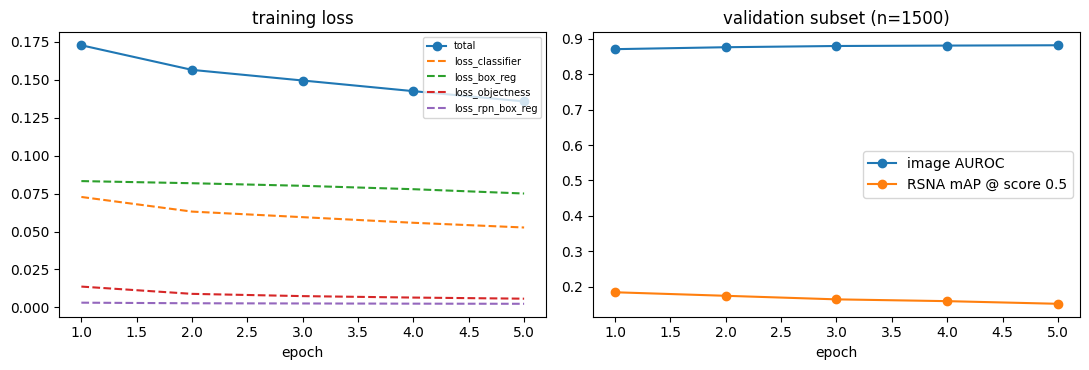

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hist_df.epoch, hist_df.train_loss, marker="o", label="total")
for k in ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]:
    if k in hist_df: axes[0].plot(hist_df.epoch, hist_df[k], ls="--", label=k)
axes[0].set(title="training loss", xlabel="epoch"); axes[0].legend(fontsize=7)
axes[1].plot(hist_df.epoch, hist_df["val_image_auroc"], marker="o", label="image AUROC")
axes[1].plot(hist_df.epoch, hist_df["val_rsna_map@0.5"], marker="o", label="RSNA mAP @ score 0.5")
axes[1].set(title=f"validation subset (n={len(val_subset)})", xlabel="epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/training.png", dpi=150); plt.show()

## 7. Box threshold, detection metrics and confusion matrix
The box-confidence threshold is chosen on the **full validation set** to maximise the RSNA competition metric (mean over IoU 0.40–0.75 of TP / (TP + FP + FN)). Boxes above it are the ones drawn and used for severity.

chosen box score threshold = 0.7  (val RSNA mAP = 0.2224)


,test
rsna_map_test,0.2300
image_auroc_test,0.8842
image_auprc_test,0.7084
accuracy,0.8389
balanced_accuracy,0.7832
precision,0.6321
recall,0.6818
specificity,0.8846
f1,0.6560


'no opacity anywhere' accuracy would be 0.775

              precision    recall  f1-score   support

  No opacity     0.9053    0.8846    0.8948      3101
     Opacity     0.6321    0.6818    0.6560       902

    accuracy                         0.8389      4003
   macro avg     0.7687    0.7832    0.7754      4003
weighted avg     0.8437    0.8389    0.8410      4003



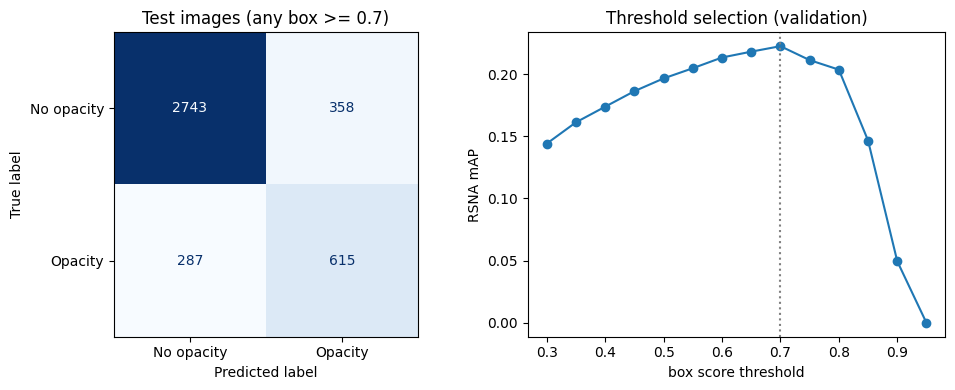

In [11]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score, average_precision_score)

pred_va = predict(model, list(id_va))
thr_grid = np.round(np.arange(0.30, 0.951, 0.05), 2)
map_va = pd.Series({t: rsna_map(pred_va, id_va, t) for t in thr_grid}, name="val RSNA mAP")
BOX_THR = float(map_va.idxmax())
print(f"chosen box score threshold = {BOX_THR}  (val RSNA mAP = {map_va.max():.4f})")

pred_te = predict(model, list(id_te))
y_te = TARGET.loc[id_te].values
ms_te = max_score(pred_te, id_te)
yhat_te = (ms_te >= BOX_THR).astype(int)
det_metrics = {
    "rsna_map_test": rsna_map(pred_te, id_te, BOX_THR),
    "image_auroc_test": float(roc_auc_score(y_te, ms_te)),
    "image_auprc_test": float(average_precision_score(y_te, ms_te)),
    "accuracy": float(accuracy_score(y_te, yhat_te)), "balanced_accuracy": float(balanced_accuracy_score(y_te, yhat_te)),
    "precision": float(precision_score(y_te, yhat_te, zero_division=0)), "recall": float(recall_score(y_te, yhat_te)),
    "specificity": float(((yhat_te == 0) & (y_te == 0)).sum() / max((y_te == 0).sum(), 1)),
    "f1": float(f1_score(y_te, yhat_te)),
}
display(pd.Series(det_metrics).round(4).to_frame("test"))
print(f"'no opacity anywhere' accuracy would be {1 - y_te.mean():.3f}\n")
print(classification_report(y_te, yhat_te, target_names=["No opacity", "Opacity"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, yhat_te), display_labels=["No opacity", "Opacity"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title(f"Test images (any box >= {BOX_THR})")
axes[1].plot(map_va.index, map_va.values, marker="o"); axes[1].axvline(BOX_THR, color="grey", ls=":")
axes[1].set(xlabel="box score threshold", ylabel="RSNA mAP", title="Threshold selection (validation)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/detection_confusion_threshold.png", dpi=150); plt.show()

## 8. Severity score and its validation
Predicted severity is compared with the **same score computed from the radiologists' boxes**. If the zone scoring is meaningful, the two should correlate on images that have opacity.

Spearman(predicted vs radiologist-box severity): opacity images rho=0.595 (p=1.4e-87) | all test images rho=0.599


,brixia_total,gt_brixia_total,n_boxes
class,,,
Lung Opacity,5.27,5.93,1.04
No Lung Opacity / Not Normal,1.21,0.00,0.25
Normal,0.01,0.00,0.00


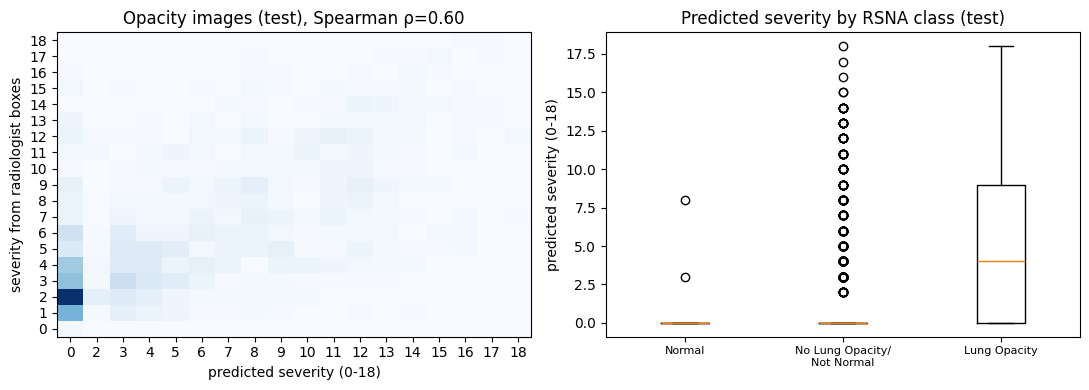

In [12]:
from scipy.stats import spearmanr

def severity_table(preds, pids):
    rows = []
    for p in pids:
        b, s = preds[p]
        sev = severity_from_boxes(b[s >= BOX_THR])
        gt = severity_from_boxes(BOXES[p])
        rows.append({"patientId": p, "Target": int(TARGET.loc[p]), "max_score": float(s.max()) if len(s) else 0.0,
                     "n_boxes": int((s >= BOX_THR).sum()), "brixia_total": sev["brixia_total"], "bilateral": sev["bilateral"],
                     "covered_frac": sev["covered_frac"], "band": sev["band"], "gt_brixia_total": gt["brixia_total"],
                     **{f"z_{k}": v for k, v in sev["zone_grades"].items()}})
    return pd.DataFrame(rows).merge(img[["patientId", "class", "sex", "age", "age_band", "view", "n_gt_boxes"]], on="patientId")

sev_va, sev_te = severity_table(pred_va, id_va), severity_table(pred_te, id_te)
pos_te = sev_te[sev_te.Target == 1]
rho, pval = spearmanr(pos_te.brixia_total, pos_te.gt_brixia_total) if len(pos_te) > 2 else (np.nan, np.nan)
rho_all, _ = spearmanr(sev_te.brixia_total, sev_te.gt_brixia_total)
print(f"Spearman(predicted vs radiologist-box severity): opacity images rho={rho:.3f} (p={pval:.1e}) | all test images rho={rho_all:.3f}")
display(sev_te.groupby("class")[["brixia_total", "gt_brixia_total", "n_boxes"]].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ct = pd.crosstab(pos_te.gt_brixia_total, pos_te.brixia_total)
axes[0].imshow(ct.values, cmap="Blues", aspect="auto", origin="lower")
axes[0].set_xticks(range(len(ct.columns))); axes[0].set_xticklabels(ct.columns)
axes[0].set_yticks(range(len(ct.index))); axes[0].set_yticklabels(ct.index)
axes[0].set(xlabel="predicted severity (0-18)", ylabel="severity from radiologist boxes", title=f"Opacity images (test), Spearman ρ={rho:.2f}")
order = [c for c in ["Normal", "No Lung Opacity / Not Normal", "Lung Opacity"] if c in sev_te["class"].unique()]
axes[1].boxplot([sev_te.loc[sev_te["class"] == c, "brixia_total"] for c in order])
axes[1].set_xticks(range(1, len(order) + 1)); axes[1].set_xticklabels([c.replace(" / ", "/\n") for c in order], fontsize=8)
axes[1].set(ylabel="predicted severity (0-18)", title="Predicted severity by RSNA class (test)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/severity_validation.png", dpi=150); plt.show()

## 9. Severity → calibrated probability `p_img`, and β
Logistic regression fitted on **validation** images: features `logit(max box score)` and `severity total`; target = opacity present.

p_img = sigmoid(0.816*logit(max_score) + 0.068*severity + -1.284)


,n,prevalence,auroc,auprc,brier,brier_reference,brier_skill_score,log_loss,ece
val,4003.0,0.2253,0.8805,0.6902,0.1109,0.1746,0.3649,0.3508,0.0179
test,4003.0,0.2253,0.8834,0.7023,0.1081,0.1746,0.3808,0.3508,0.0111



β (reliability weight) = clip(BSS_test, 0, 1) = 0.3808


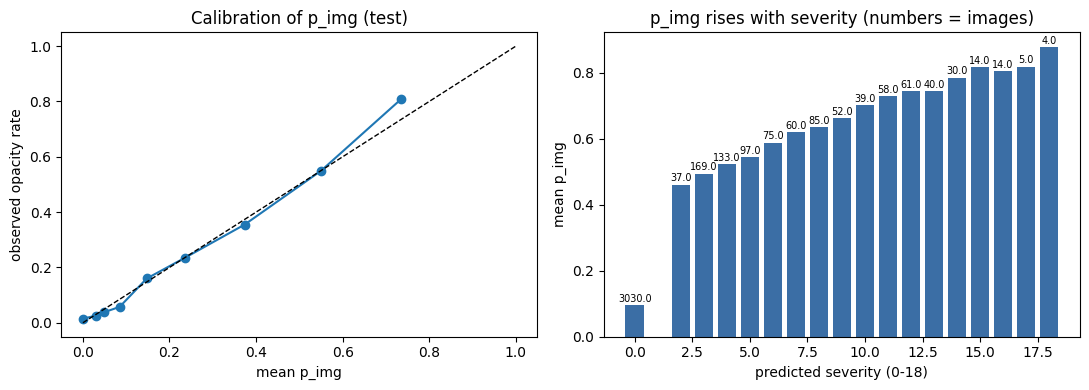

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

X_va = calib_features(sev_va.max_score, sev_va.brixia_total); y_va = sev_va.Target.values
X_te = calib_features(sev_te.max_score, sev_te.brixia_total); y_te2 = sev_te.Target.values
lr = LogisticRegression(C=1.0, max_iter=1000).fit(X_va, y_va)
COEF, INTERCEPT = lr.coef_[0].tolist(), float(lr.intercept_[0])
print(f"p_img = sigmoid({COEF[0]:.3f}*logit(max_score) + {COEF[1]:.3f}*severity + {INTERCEPT:.3f})")
sev_va["p_img"] = lr.predict_proba(X_va)[:, 1]; sev_te["p_img"] = lr.predict_proba(X_te)[:, 1]

def ece(y, p, bins=10):
    e = np.linspace(0, 1, bins + 1); i = np.clip(np.digitize(p, e) - 1, 0, bins - 1)
    return float(sum(abs(p[i == b].mean() - y[i == b].mean()) * (i == b).mean() for b in range(bins) if (i == b).any()))

def evaluate(y, p):
    br = brier_score_loss(y, p); ref = brier_score_loss(y, np.full_like(p, BASE_RATE_TRAIN))
    return dict(n=int(len(y)), prevalence=float(y.mean()), auroc=float(roc_auc_score(y, p)), auprc=float(average_precision_score(y, p)),
                brier=float(br), brier_reference=float(ref), brier_skill_score=float(1 - br / ref),
                log_loss=float(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))), ece=ece(y, p))

prob_metrics = {"val": evaluate(y_va, sev_va.p_img.values), "test": evaluate(y_te2, sev_te.p_img.values)}
BETA = float(np.clip(prob_metrics["test"]["brier_skill_score"], 0, 1))
display(pd.DataFrame(prob_metrics).T.round(4))
print(f"\nβ (reliability weight) = clip(BSS_test, 0, 1) = {BETA:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fr, mp = calibration_curve(y_te2, sev_te.p_img, n_bins=10, strategy="quantile")
axes[0].plot(mp, fr, marker="o"); axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="mean p_img", ylabel="observed opacity rate", title="Calibration of p_img (test)")
g = sev_te.groupby("brixia_total").p_img.agg(["mean", "size"])
axes[1].bar(g.index, g["mean"], color="#3b6ea5")
for x, (m, n) in g.iterrows(): axes[1].text(x, m + 0.01, str(n), ha="center", fontsize=7)
axes[1].set(xlabel="predicted severity (0-18)", ylabel="mean p_img", title="p_img rises with severity (numbers = images)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/pimg_calibration_by_severity.png", dpi=150); plt.show()

## 10. Subgroup audit (sex, age band, view)
Same idea as the fairness audit in Notebook 1, using the DICOM headers. RSNA has no race/ethnicity field.
AP (bedside) films are taken on sicker patients, so a higher opacity rate for AP is expected; the question is whether discrimination (AUROC) and calibration hold across groups.

In [14]:
def audit(df, col):
    rows = []
    for g, s in df.groupby(col):
        yhat = (s.max_score >= BOX_THR).astype(int)
        pos_, neg_ = s.Target == 1, s.Target == 0
        rows.append({"attribute": col, "group": g, "n": len(s), "opacity_rate": s.Target.mean(), "mean_p_img": s.p_img.mean(),
                     "AUROC": roc_auc_score(s.Target, s.p_img) if s.Target.nunique() == 2 else np.nan,
                     "TPR": yhat[pos_].mean() if pos_.any() else np.nan, "FPR": yhat[neg_].mean() if neg_.any() else np.nan,
                     "mean_severity_if_opacity": s.loc[pos_, "brixia_total"].mean()})
    return pd.DataFrame(rows)

audit_df = pd.concat([audit(sev_te, c) for c in ["sex", "age_band", "view"]], ignore_index=True)
display(audit_df.round(3))

,attribute,group,n,opacity_rate,mean_p_img,AUROC,TPR,FPR,mean_severity_if_opacity
0,sex,F,1757,0.211,0.210,0.890,0.692,0.110,5.059
1,sex,M,2246,0.237,0.226,0.878,0.675,0.120,5.414
2,age_band,40-59,1748,0.216,0.223,0.880,0.698,0.125,5.584
3,age_band,60-74,857,0.209,0.200,0.870,0.637,0.112,4.028
4,age_band,75+,118,0.237,0.231,0.892,0.679,0.089,4.857
5,age_band,<40,1279,0.249,0.225,0.895,0.689,0.107,5.629
6,age_band,Unknown,1,0.000,0.001,NaN,NaN,0.000,NaN
7,view,AP,1781,0.388,0.369,0.841,0.781,0.253,6.359
8,view,PA,2222,0.095,0.099,0.845,0.355,0.041,1.697


## 11. Example detections (test)

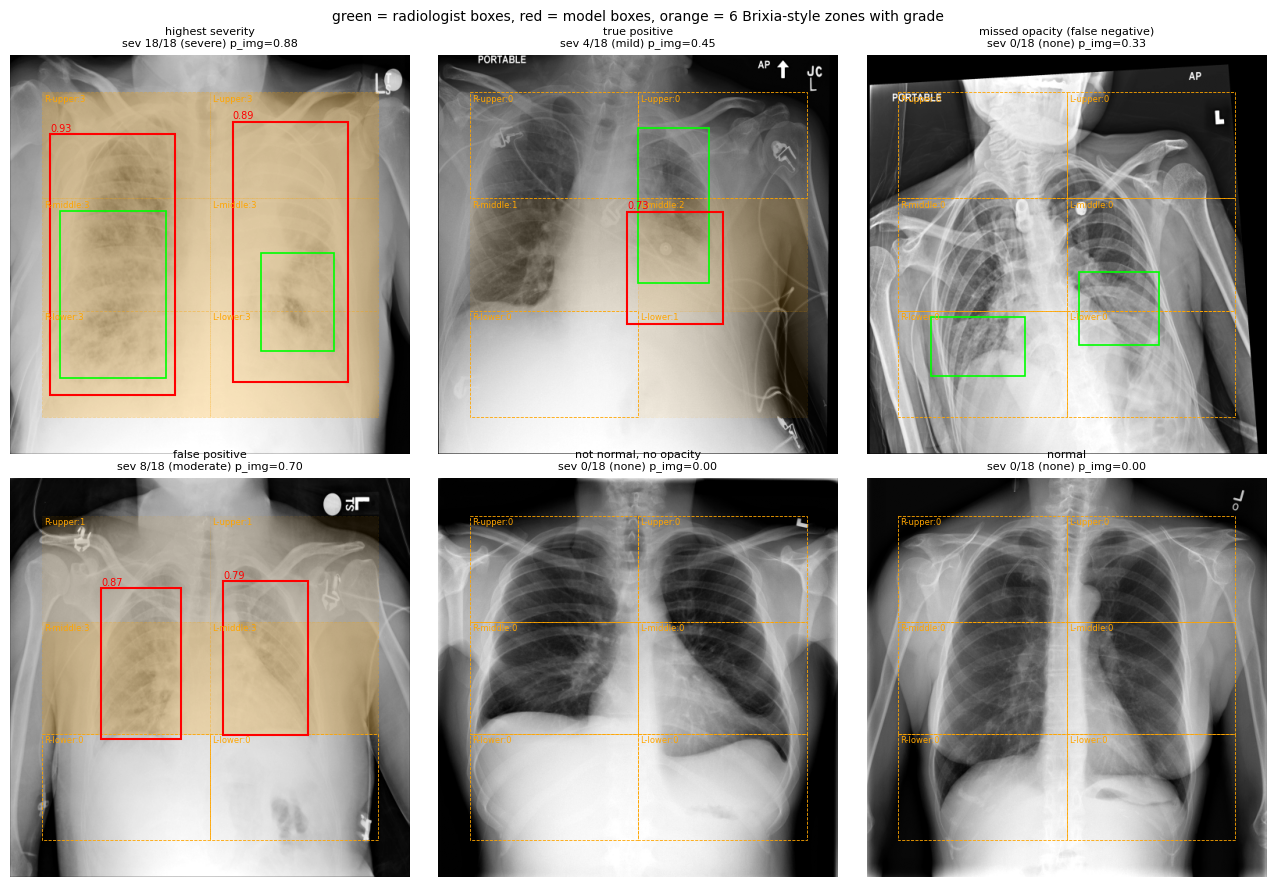

In [15]:
from img_inference import zone_slices
from matplotlib.patches import Rectangle

def show(ax, p, title):
    im = cv2.imread(os.path.join(CACHE_DIR, f"{p}.png"), cv2.IMREAD_GRAYSCALE)
    b, s = pred_te[p]; keep = s >= BOX_THR
    sev = severity_from_boxes(b[keep])
    a = {"image": im, "boxes": b[keep], "scores": s[keep], **sev,
         "p_img": float(sev_te.set_index("patientId").loc[p, "p_img"])}
    img_inference.ImagingRiskModel.draw(None, a, ax=ax, gt_boxes=BOXES[p],
                                        title=f"{title}\nsev {sev['brixia_total']}/18 ({sev['band']}) p_img={a['p_img']:.2f}")

st = sev_te.set_index("patientId")
def pick(mask, how="sample"):
    sub = st[mask]
    if not len(sub):
        return None
    return sub.sort_values("brixia_total").index[-1] if how == "top" else sub.sample(1, random_state=1).index[0]
cands = [("highest severity", pick(st.n_boxes > 0, "top")),
         ("true positive", pick((st.Target == 1) & (st.n_boxes > 0))),
         ("missed opacity (false negative)", pick((st.Target == 1) & (st.n_boxes == 0))),
         ("false positive", pick((st.Target == 0) & (st.n_boxes > 0))),
         ("not normal, no opacity", pick((st["class"] == "No Lung Opacity / Not Normal") & (st.n_boxes == 0))),
         ("normal", pick((st["class"] == "Normal") & (st.n_boxes == 0)))]
picks = [(t, p) for t, p in cands if p is not None]
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, (t, p) in zip(axes.ravel(), picks):
    show(ax, p, t)
for ax in axes.ravel()[len(picks):]:
    ax.axis("off")
fig.suptitle("green = radiologist boxes, red = model boxes, orange = 6 Brixia-style zones with grade", fontsize=10)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/examples.png", dpi=150); plt.show()

## 12. Save artifacts and the demo image pool
The demo pool holds test images (never used for training or calibration) in three tiers — **high**, **moderate** and **low/none** severity — so Notebook 4 can draw the t = 0 image and a *more severe* follow-up image for the simulated re-imaging.

In [16]:
import sklearn
torch.save(model.state_dict(), f"{OUT_DIR}/fasterrcnn_rsna.pth")
json.dump({"features": ["logit(max_score)", "brixia_total"], "coef": COEF, "intercept": INTERCEPT,
           "target": "image-level opacity present (RSNA Target)"}, open(f"{OUT_DIR}/calibrator.json", "w"), indent=2)
json.dump({"detector": {"arch": "fasterrcnn_resnet50_fpn", "num_classes": 2, "img_size": IMG_SIZE, "orig_size": ORIG_SIZE,
                        "score_thresh": 0.05, "nms_thresh": 0.5, "detections_per_img": 10},
           "box_score_threshold": BOX_THR, "zones": ZONES, "zone_cfg": ZONE_CFG,
           "severity_bands": img_inference.SEVERITY_BANDS,
           "training": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "neg_ratio": NEG_RATIO, "pretrained": PRETRAINED}},
          open(f"{OUT_DIR}/model_config.json", "w"), indent=2)

metrics = {"model": "Faster R-CNN ResNet-50 FPN + Brixia-style severity + logistic calibration",
           "base_rate_train": BASE_RATE_TRAIN, "beta": BETA,
           "beta_rule": "clip(test Brier skill score of p_img vs training opacity rate, 0, 1)",
           "box_score_threshold": BOX_THR, "detection_test": det_metrics, "p_img": prob_metrics,
           "severity_spearman_opacity_images": float(rho), "severity_spearman_all": float(rho_all),
           "val_map_by_threshold": {str(k): v for k, v in map_va.items()},
           "split": {"seed": SEED, "n_train": int(len(id_tr)), "n_val": int(len(id_va)), "n_test": int(len(id_te))},
           "versions": {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
                        "sklearn": sklearn.__version__, "numpy": np.__version__}}
json.dump(metrics, open(f"{OUT_DIR}/metrics.json", "w"), indent=2, default=float)
hist_df.to_csv(f"{OUT_DIR}/training_history.csv", index=False)
audit_df.to_csv(f"{OUT_DIR}/subgroup_audit.csv", index=False)

# all test predictions (boxes in 512-px coordinates)
sev_te["pred_boxes_512"] = sev_te.patientId.map(lambda p: json.dumps(np.round(pred_te[p][0][pred_te[p][1] >= BOX_THR], 1).tolist()))
sev_te["pred_scores"] = sev_te.patientId.map(lambda p: json.dumps(np.round(pred_te[p][1][pred_te[p][1] >= BOX_THR], 3).tolist()))
sev_te["gt_boxes_512"] = sev_te.patientId.map(lambda p: json.dumps(np.round(BOXES[p], 1).tolist()))
sev_te.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

# demo pool: three severity tiers from the test set
srt = sev_te.sort_values(["brixia_total", "p_img"])
high = srt[srt.brixia_total >= 5].tail(DEMO_PER_TIER)
mod  = srt[(srt.brixia_total >= 1) & (srt.brixia_total < 5)]
mod  = mod.sample(min(DEMO_PER_TIER, len(mod)), random_state=SEED)
low  = srt[(srt.brixia_total == 0) & (srt.Target == 0)]
low  = low.sample(min(DEMO_PER_TIER, len(low)), random_state=SEED)
demo = pd.concat([high.assign(tier="high"), mod.assign(tier="moderate"), low.assign(tier="low")])
for p in demo.patientId:
    shutil.copy(os.path.join(CACHE_DIR, f"{p}.png"), os.path.join(DEMO_DIR, f"{p}.png"))
demo.to_csv(f"{OUT_DIR}/demo_pool.csv", index=False)
print("saved. demo pool:", demo.tier.value_counts().to_dict())

saved. demo pool: {'high': 50, 'moderate': 50, 'low': 50}


## 13. Reload check and packaging

1) same layers: True | identical weights: True | backbone norm layer: FrozenBatchNorm2d
2) batched re-prediction reproduces stored severity: True


,patientId,tier,sev_stored,sev_assess,p_stored,p_assess,sev_diff,p_diff
0,370e4257,high,14,14,0.7987,0.7962,0,0.0025
1,b56cf994,high,14,14,0.7997,0.7966,0,0.0031
2,d094558c,high,14,14,0.8056,0.8041,0,0.0015
3,5bad55a2,high,14,15,0.8104,0.8186,1,0.0082
4,53b42127,high,14,14,0.8138,0.8120,0,0.0018
5,97d33835,high,14,14,0.8257,0.8245,0,0.0012
6,646c5b26,high,14,14,0.8320,0.8309,0,0.0011
7,57835e6c,high,14,14,0.8390,0.8366,0,0.0024
8,b006df68,high,14,14,0.8410,0.8390,0,0.0021
9,f919d3cb,high,14,14,0.8433,0.8401,0,0.0032


3) assess() vs stored: max severity diff = 1 | max p_img diff = 0.0082 | exact severity match on 95% of images

reload OK | β = 0.3808 | base rate = 0.2253 | box threshold = 0.7
{'n_boxes': 2, 'brixia_total': 18, 'band': 'severe', 'bilateral': True, 'max_score': 0.9446041584014893, 'p_img': 0.904794003948323, 'delta_img': 3.486754439501923}
zone grades: {'R-upper': 3, 'R-middle': 3, 'R-lower': 3, 'L-upper': 3, 'L-middle': 3, 'L-lower': 3}


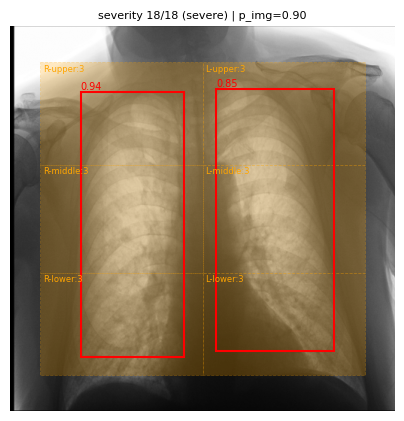

In [23]:
importlib.reload(img_inference)
from img_inference import ImagingRiskModel
im = ImagingRiskModel(OUT_DIR)

# 1) weights on disk == weights in memory, same architecture
trained, loaded = model.state_dict(), im.model.state_dict()
same_keys = set(trained) == set(loaded)
same_w = same_keys and all(torch.equal(loaded[k].cpu(), trained[k].cpu()) for k in trained)
print(f"1) same layers: {same_keys} | identical weights: {same_w} | "
      f"backbone norm layer: {type(im.model.backbone.body.bn1).__name__}")
assert same_w, "reloaded model differs from the trained model"

# 2) same batched/AMP path as the notebook -> must reproduce the stored test predictions
check = demo.patientId.tolist()[:min(20, len(demo))]
pred_re = predict(im.model, check)
ref = sev_te.set_index("patientId")
same_pred = all(severity_from_boxes(pred_re[p][0][pred_re[p][1] >= BOX_THR])["brixia_total"] == ref.loc[p, "brixia_total"]
                for p in check)
print("2) batched re-prediction reproduces stored severity:", same_pred)

# 3) assess() = single image, full precision (what Notebook 4 uses) -> allow small fp16-vs-fp32 drift
rows = []
for p in check:
    a = im.assess(os.path.join(DEMO_DIR, f"{p}.png"))
    rows.append({"patientId": p[:8], "tier": demo.set_index("patientId").loc[p, "tier"],
                 "sev_stored": int(ref.loc[p, "brixia_total"]), "sev_assess": a["brixia_total"],
                 "p_stored": float(ref.loc[p, "p_img"]), "p_assess": a["p_img"]})
chk = pd.DataFrame(rows)
chk["sev_diff"] = (chk.sev_assess - chk.sev_stored).abs()
chk["p_diff"] = (chk.p_assess - chk.p_stored).abs()
display(chk.round(4))
print(f"3) assess() vs stored: max severity diff = {chk.sev_diff.max()} | max p_img diff = {chk.p_diff.max():.4f} | "
      f"exact severity match on {(chk.sev_diff == 0).mean():.0%} of images")
assert chk.sev_diff.max() <= 2 and chk.p_diff.max() < 0.05, "assess() differs more than fp16-vs-fp32 drift explains"
print(f"\nreload OK | β = {im.beta:.4f} | base rate = {im.base_rate:.4f} | box threshold = {im.box_thr}")

p = demo[demo.tier == "high"].patientId.iloc[-1] if (demo.tier == "high").any() else demo.patientId.iloc[0]
a = im.assess(os.path.join(DEMO_DIR, f"{p}.png"))
print({k: a[k] for k in ["n_boxes", "brixia_total", "band", "bilateral", "max_score", "p_img", "delta_img"]})
print("zone grades:", a["zone_grades"])
plt.figure(figsize=(5, 5)); im.draw(a); plt.show()

In [24]:
zip_path = shutil.make_archive(os.path.join(WORK_DIR, "artifacts_imaging"), "zip", OUT_DIR)
print("zip:", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)\n")
n_demo = len(os.listdir(DEMO_DIR))
for root, _, fs in os.walk(OUT_DIR):
    if root == DEMO_DIR:
        continue
    for f in sorted(fs):
        pth = os.path.join(root, f)
        print(f"{os.path.relpath(pth, OUT_DIR):40s} {os.path.getsize(pth)/1e3:10.1f} KB")
print(f"demo_images/  ({n_demo} PNGs)")

zip: /kaggle/working/artifacts_imaging.zip (174.5 MB)

calibrator.json                                 0.2 KB
demo_pool.csv                                  42.9 KB
fasterrcnn_rsna.pth                        165730.1 KB
img_inference.py                                8.4 KB
metrics.json                                    2.2 KB
model_config.json                               0.8 KB
subgroup_audit.csv                              1.2 KB
test_predictions.csv                          790.0 KB
training_history.csv                            0.9 KB
plots/detection_confusion_threshold.png        70.4 KB
plots/examples.png                           1635.3 KB
plots/pimg_calibration_by_severity.png         84.9 KB
plots/severity_validation.png                  80.0 KB
plots/training.png                             82.5 KB
demo_images/  (150 PNGs)


### Values used later
- `metrics.json → beta`, `base_rate_train` (for `Δ_img = logit(p_img) − logit(base_rate_train)`)
- `ImagingRiskModel.assess()` → boxes, zone grades, severity total/band, `p_img`, `delta_img`; `.draw()` for the report image
- `demo_pool.csv` + `demo_images/` → t = 0 image and simulated follow-up images (by tier)

**Limitations to state:** zones are fixed image regions, not segmented lungs; RSNA has no severity labels, so `p_img` is calibrated to "opacity present" and severity is validated only against the same score from radiologist boxes; β measures how well this model does *its own* task (opacity), not how much an opacity changes mortality; re-imaging uses a different patient's image (simulation).